# CPIT: decisión, datos y procedencia

**Pregunta:** ¿Cómo convierten las precedencias y capacidades una clasificación por valor en un plan CPIT por período?

**Nivel**: 1

**Prerrequisitos**: ninguno

**Lectura**: 18 minutos

## Objetivos

Defina la decisión CPIT, siga casos versionados y construya una primera programación mediante el paquete. Al terminar, podrá distinguir un pit de una secuencia de producción y explicar el límite de los agregados.

## Preparación

Instale desde la raíz el entorno fijado con estas versiones. La celda informa las versiones realmente importadas.

```bash
pip install oreblocks==0.6.6 numpy==2.5.1 scipy==1.18.1 matplotlib==3.11.2
```

In [1]:
# Importar API y comprobar versiones.
import importlib.metadata as metadata
import json
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt
sys.path.insert(0,str(Path('../../../data-pipeline').resolve()))
from pipeline.io.schema import Case,DepositSpec,Scenario
from pipeline.model.instances import build_instance
import oreblocks as ob
for package in ('oreblocks','numpy','scipy','matplotlib'):
    print(package,metadata.version(package))

oreblocks 0.6.6
numpy 2.5.1
scipy 1.18.1
matplotlib 3.11.2


## Datos

PhaseFlow mantiene el generador determinista y el constructor de instancias; su código usa licencia MIT. El caso declara veta, semilla 31, tamaño 4×4×3, cuatro períodos y capacidades; no es dato de terreno. twin-porphyry-s es otro manifiesto derivado. Newman1 es un agregado del benchmark MineLib; los archivos por bloque tienen condiciones académicas de descarga y no se redistribuyen.

Procedencia por archivo: los agregados versionados son data/derived/manifests/newman1-published.json y data/derived/manifests/twin-porphyry-s.json. MineLib publica su registro en https://minelib.org/v1/Results.xhtml; MineLib mantiene el benchmark y sus archivos fuente tienen licencia de descarga académica. El generador sintético pertenece a PhaseFlow, https://github.com/fsantibanezleal/CAOS_PhaseFlow, bajo licencia MIT; su implementación está en data-pipeline/pipeline/model/instances.py. La semilla y el escenario del ejemplo se declaran en el código.

In [2]:
# Construir la instancia con el pipeline y leer agregados versionados.
case = Case(
    id='nb-vein-4x4x3',
    category='teaching',
    title_en='Small vein twin',
    title_es='Gemelo pequeño de veta',
    deposit=DepositSpec(kind='twin', archetype='vein', dims=(4, 4, 3), seed=31),
    scenario=Scenario(
        periods=4, discount_rate=0.08,
        capacity_fraction=(0.70, 0.50),
        resource_names=('mining', 'processing'),
    ),
)
instance=build_instance(case)
newman=json.loads(Path('../../../data/derived/manifests/newman1-published.json').read_text(encoding='utf-8'))
twin=json.loads(Path('../../../data/derived/manifests/twin-porphyry-s.json').read_text(encoding='utf-8'))
print('contrato aceptado:',instance.report.ok,'| bloques:',instance.n_blocks)
print('casos versionados:',newman.get('case_id',newman.get('case')),twin.get('case_id',twin.get('case')))

contrato aceptado: True | bloques: 48
casos versionados: newman1-published twin-porphyry-s


## Método

La extracción acumulada x(i,t) respeta precedencias x(i,t) ≤ x(j,t). El incremento del período es x(i,t) − x(i,t−1), cuyo valor se descuenta. Chicoisne et al. (2012), https://doi.org/10.1287/opre.1120.1050, fundamentan la relajación paramétrica de cierres máximos. El notebook usa el pipeline y OreBlocks; no copia la implementación. Primero obtendremos cotas por recurso, después programaremos y finalmente validaremos.

Un pit último y un plan de producción responden preguntas distintas. El pit pregunta qué bloques pueden extraerse juntos respetando las precedencias de talud. CPIT agrega tiempo: cada bloque se asigna a un período o queda sin extraer, mientras las capacidades de mina y planta limitan cada período. Un bloque valioso puede retrasarse por sus requisitos, por otro recurso limitante o por el descuento. La canalización de PhaseFlow y OreBlocks implementan estas decisiones acopladas; ordenar valores por sí solo omite la restricción central.

Para la extracción acumulada x(i,t), un arco desde el requisito j hasta el bloque i impone x(i,t) <= x(j,t). La decisión del período es x(i,t)-x(i,t-1) y el objetivo descuenta su valor. Esta notación explica el modelo, pero el notebook no lo reimplementa. PhaseFlow construye el caso declarado y el paquete OreBlocks fijado lo planifica. Chicoisne et al. (2012), DOI 10.1287/opre.1120.1050, derivan la relajación de un recurso usando cierres máximos anidados. El resultado motiva una cota; no convierte un plan heurístico en una solución entera exacta.

El significado de los datos forma parte del cálculo. El constructor del producto crea valores, precedencias, coeficientes de recursos y alternativas de destino desde el depósito y escenario; luego ejecuta los controles del contrato PhaseFlow. Los fallos dimensionales, de capacidad y precedencia deben resolverse antes de confiar en el resultado del solver. Esta lección usa un gemelo determinista de veta, semilla 31, dimensiones 4 por 4 por 3 y cuatro períodos. La escala pequeña expone valores intermedios; no estima una mina operativa ni reproduce un benchmark publicado.

Newman1 de MineLib aparece solo como evidencia agregada. Su manifiesto versionado registra el escenario y resultados, mientras los archivos originales por bloque permanecen sujetos a las condiciones de descarga académica de MineLib y no se redistribuyen. El manifiesto muestra lo registrado por PhaseFlow para ese caso, pero no reconstruye los bloques ausentes ni reproduce independientemente la resolución. La lección sintética es otro caso. Separar la evidencia evita tomar prestada una autoridad de benchmark que no corresponde.

TopoSort con valor esperado considera bloques elegibles según precedencia y aplica el peso del paquete al decidir qué programar. Sus asignaciones por período, VPN y cota son resultados intermedios útiles. Los bloques no extraídos llevan un índice centinela negativo. Resumiremos las asignaciones por período en lugar de imprimir un vector opaco, y compararemos toneladas extraídas con capacidad. La figura muestra presión de recursos, pero no dibuja precedencias y no reemplaza la validación del paquete.

Los controles examinan propiedades distintas: el valor factible no debe exceder la cota superior, la construcción de dualidad debe coincidir dentro de tolerancia y el orden de entrada no debe alterar materialmente el resultado. Superarlos respalda la consistencia computacional interna. No valida supuestos geológicos, no prueba optimalidad entera global ni determina el tiempo a escala de producción. La conclusión se limita a esta semilla y escenario declarados.


Paso 1. Calcule la cota de cada recurso por separado para encontrar la más ajustada.

In [3]:
# Calcular la cota de relajación para cada recurso.
relaxations = [
    ob.cpit_lp_relaxation(
        instance.cpit, instance.precedence, resource=resource
    )
    for resource in range(instance.cpit.coef.shape[0])
]
for item in relaxations:
    print(
        'recurso:', instance.cpit.resource_names[item.resource],
        '| cota:', round(item.bound, 2),
        '| cierres:', item.closure_solves,
    )

recurso: mining | cota: 333680.0 | cierres: 31
recurso: processing | cota: 284685.82 | cierres: 57


Paso 2. Construya un plan Expected, que considera elegibilidad por precedencia.

In [4]:
# Ejecutar TopoSort e inspeccionar VPN y bloques extraídos.
schedule,_=ob.solve_cpit(instance.cpit,instance.precedence,method='expected',local_search=False)
print(
    'metodo', schedule.method, 'VPN', round(schedule.npv, 2),
    'cota', round(schedule.bound, 2), 'bloques extraidos', schedule.mined_blocks,
)

metodo toposort:expected[r1] VPN 179191.57 cota 284685.82 bloques extraidos 16


Paso 3. Valide dirección de cota, dualidad e invariancia al orden.

In [5]:
# Aplicar los controles independientes del paquete.
controls=ob.run_controls(instance.cpit,instance.precedence,schedule)
print(controls.__dict__)

{'duality_set_matches': True, 'duality_bound_error': 0.0, 'bound_geq_feasible': True, 'order_invariant': True, 'order_invariance_error': 0.0}


El gráfico muestra toneladas por período y la capacidad declarada. Facilita ver presión sobre la mina, pero no dibuja precedencias ni reemplaza controles calculados sobre el plan completo.

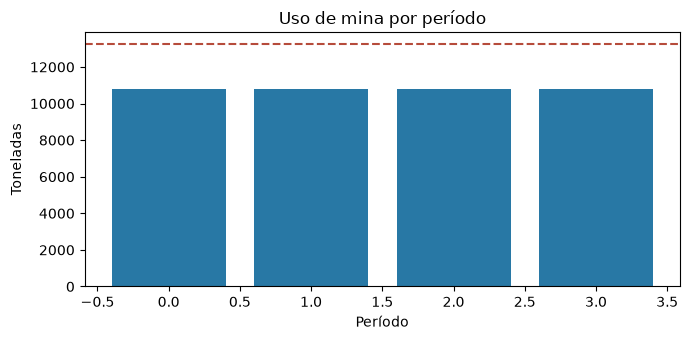

In [6]:
# Graficar extracción por período y límite.
fig,ax=plt.subplots(figsize=(7,3.5))
ax.bar(np.arange(instance.cpit.n_periods),schedule.per_period_resource[0],color='#2878a5')
ax.axhline(instance.cpit.limit[0,0],color='#b64b3b',linestyle='--')
ax.set(
    title='Uso de mina por período',
    xlabel='Período', ylabel='Toneladas',
)
fig.tight_layout()
plt.show()

## Resultados

**Respuesta:** el método Expected calculó un VPN de 179191.57 para 16 bloques; su cota superior es 284685.82 y la brecha medida es 37.056%. El gráfico compara toneladas por período con la capacidad. El resultado corresponde a una instancia sintética de enseñanza, no a MineLib ni a una prueba de optimalidad.

In [7]:
# Informar la respuesta calculada y la brecha.
print('VPN',round(schedule.npv,2),'| bloques extraídos',schedule.mined_blocks)
print('cota',round(schedule.bound,2),'| brecha %',round(100*(schedule.bound-schedule.npv)/schedule.bound,3))

VPN 179191.57 | bloques extraídos 16
cota 284685.82 | brecha % 37.056


## Resumen

El pipeline deja trazable la procedencia y valida el contrato; OreBlocks produce el plan y los controles revisan su consistencia computacional. El resultado es heurístico y se limita a las capacidades y economía declaradas.

## Referencias

- Chicoisne et al. (2012): https://doi.org/10.1287/opre.1120.1050
- Rivera Letelier et al. (2020): https://doi.org/10.1287/opre.2019.1965
- MineLib Newman1 aggregate: https://minelib.org/v1/Results.xhtml
- PhaseFlow dossiers: docs/methodologies/02_the-bound.md; docs/cases/01_newman1-published.md; docs/cases/04_twin-porphyry-s.md
- Repositorio PhaseFlow y generador de gemelos sintéticos: https://github.com/fsantibanezleal/CAOS_PhaseFlow